# Jev end-to-end financial NLP benchmark

Run OpenCode Zen’s **Jev 1.13 Free** on held-out examples for sentiment classification, sentiment regression (-1 to 1), and multi-label ticker prediction. This notebook makes inference calls only; it does not train models. Attach your benchmark CSV dataset as a Kaggle input and add your OpenCode Zen key later as a Kaggle Secret named `OPENCODE_API_KEY`.

**Before running:** attach the benchmark dataset and enable Internet in Kaggle. Start with the small sample limits below to control runtime. Set a limit to `None` to process the full holdout split. Results and resumable response caches are written under `/kaggle/working/jev_financial_nlp/`.

The notebook sends typed `choice`, `score`, and `noul` questions to OpenCode Zen’s Jev System One endpoint. See [OpenCode Zen Jev documentation](https://opencode.ai/docs/en/zen/).


## 1. Dependencies

In [ ]:
%pip -q install requests pandas numpy scikit-learn matplotlib seaborn tqdm


In [12]:
import ast, json, os, re, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
    multilabel_confusion_matrix, hamming_loss, average_precision_score)
from tqdm.auto import tqdm

SEED = 42
BASE_URL = "https://opencode.ai/zen/v1"
MODEL_NAME = "jev-1.13-free"  # OpenCode Zen free model ID.
BENCHMARK_DIR = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/jev_financial_nlp")
CACHE_DIR = OUTPUT_DIR / "cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Conservative starter budgets; use None to process the entire corresponding holdout.
CLASSIFICATION_LIMIT_PER_DATASET = 40
REGRESSION_LIMIT = 60
TICKER_VALIDATION_LIMIT = 30
TICKER_TEST_LIMIT = 50
REQUEST_TIMEOUT_SECONDS = 90
MAX_RETRIES = 8  # Retries transient API and rate-limit errors.
MIN_REQUEST_INTERVAL_SECONDS = 2.5  # About 24 sequential calls per minute.
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","NVDA","META","TSLA","BRK.B","JPM","V","JNJ","WMT","PG","MA","HD","XOM","CVX","LLY","ABBV","MRK","BAC","KO","PEP","COST","AVGO","ORCL","ADBE","CRM","NFLX","AMD","INTC","CSCO","QCOM","TXN","IBM","DIS","NKE","MCD","T","PFE","UNH","CAT","GE","BA","GS","C","WFC","PYPL","UBER"]
# Optional disambiguating company names. Leave empty to use ticker symbols alone.
TICKER_ENTITY_NAMES = {}

print("Input root:", BENCHMARK_DIR)
print("Output root:", OUTPUT_DIR)
print("Ticker labels:", len(TICKERS))


Input root: /kaggle/input
Output root: /kaggle/working/jev_financial_nlp
Ticker labels: 49


## 2. Locate benchmark CSVs and load the API key

In Kaggle, save the secret as `OPENCODE_API_KEY`. This cell never displays the key. Dataset discovery searches `/kaggle/input` recursively by filename.


In [13]:
def find_csv(filename):
    hits = list(BENCHMARK_DIR.rglob(filename))
    if not hits:
        raise FileNotFoundError(f"Could not find {filename} below {BENCHMARK_DIR}. Attach the benchmark dataset as a Kaggle input.")
    return hits[0]

PATHS = {
    "phrasebank": find_csv("financial_phrasebank_50agree.csv"),
    "twitter": find_csv("twitter_financial_news_sentiment.csv"),
    "fiqa": find_csv("fiqa_2018_sentiment_regression.csv"),
    "ticker": find_csv("financial_news_ticker_linking.csv"),
}
for name, path in PATHS.items(): print(f"{name}: {path}")

# Set a Kaggle Secret named OPENCODE_API_KEY. Never print the secret value.
API_KEY = "oc_sk_5b3da200c9ad_uxbwkUFXyLQWS5eRRnaJoTIEWXGf29YE"

SESSION = requests.Session()
SESSION.headers.update({"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"})
# Optional preflight: OpenCode Zen's models endpoint may return OpenAI-compatible `data` metadata.
models_response = SESSION.get(f"{BASE_URL}/models", timeout=REQUEST_TIMEOUT_SECONDS)
models_response.raise_for_status()
model_payload = models_response.json()
model_entries = model_payload.get("models", model_payload.get("data", [])) if isinstance(model_payload, dict) else []
AVAILABLE_MODELS = [m.get("name", m.get("id", "")) for m in model_entries if isinstance(m, dict)]
print("Configured model:", MODEL_NAME)
if AVAILABLE_MODELS:
    print("Models listed by OpenCode Zen:", AVAILABLE_MODELS)
    if MODEL_NAME not in AVAILABLE_MODELS:
        raise ValueError(f"{MODEL_NAME!r} is not listed. Available IDs: {AVAILABLE_MODELS}")


phrasebank: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_phrasebank_dataset/financial_phrasebank_50agree.csv
twitter: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/twitter_financial_news_sentiment.csv
fiqa: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/fiqa_2018_sentiment_regression.csv
ticker: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_news_ticker_linking.csv
Configured model: jev-1.13-free
Models listed by OpenCode Zen: ['big-pickle', 'ling-3.1-flash-free', 'fledge-alpha-free', 'mimo-v2.5-free', 'mimo-v2.6-flash-free', 'muse-spark-1.2-contributor-free', 'muse-spark-1.3-contributor-free', 'nemotron-3.5-lightning-free', 'jev-1.13-free', 'test', 'longcat-2.5-preview-free', 'space-bunny-free', 'jev-1.13', 'claude-fable-5-1', 'claude-haiku-4-5', 'claude-opus-5-5', 'claude-sonnet-5-5', 'deepseek-v4.1-flash', 'deepseek-v4-pro', 'gemini-3.1-pro', 'gemini-3.5-flash-lite', 'gemini-3.8-flash'

## 3. API helper and resumable cache

In [14]:
def stable_id(task, row_id):
    return f"{task}__{hashlib.sha1(str(row_id).encode('utf-8')).hexdigest()}"

def cache_path(task): return CACHE_DIR / f"{task}.jsonl"

def read_cache(task):
    path = cache_path(task)
    results = {}
    if path.exists():
        with path.open(encoding="utf-8") as f:
            for line in f:
                try:
                    item = json.loads(line)
                    if item.get("ok"): results[item["id"]] = item["response"]
                except (json.JSONDecodeError, KeyError): pass
    return results

def append_cache(task, item):
    with cache_path(task).open("a", encoding="utf-8") as f:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

def retry_delay(response, attempt):
    """Honor Retry-After or use capped exponential backoff."""
    retry_after = response.headers.get("Retry-After") if response is not None else None
    if retry_after:
        try:
            return max(1.0, min(float(retry_after), 300.0))
        except ValueError:
            try:
                from email.utils import parsedate_to_datetime
                from datetime import datetime, timezone
                retry_at = parsedate_to_datetime(retry_after)
                return max(1.0, min((retry_at - datetime.now(timezone.utc)).total_seconds(), 300.0))
            except Exception:
                pass
    return min(10.0 * (2 ** attempt), 300.0)

def ask_jev(state, questions):
    body = {"model": MODEL_NAME, "state": state, "questions": questions}
    for attempt in range(MAX_RETRIES):
        try:
            response = SESSION.post(f"{BASE_URL}/systemone", json=body, timeout=REQUEST_TIMEOUT_SECONDS)
        except requests.RequestException as exc:
            if attempt + 1 >= MAX_RETRIES: raise
            delay = min(2 ** attempt, 60)
            print(f"Temporary network error; retrying in {delay}s ({attempt + 1}/{MAX_RETRIES}).")
            time.sleep(delay)
            continue
        if response.status_code == 429 or response.status_code >= 500:
            if attempt + 1 < MAX_RETRIES:
                delay = retry_delay(response, attempt)
                print(f"OpenCode Zen returned {response.status_code}; retrying in {delay:.0f}s ({attempt + 1}/{MAX_RETRIES}).")
                time.sleep(delay)
                continue
        if response.status_code >= 400:
            raise requests.HTTPError(
                f"{response.status_code} {response.reason}: {response.text[:2000]}",
                response=response,
            )
        return response.json()
    raise RuntimeError("Jev request failed after retries")
def run_cached(task, rows, question_builder, state_builder, limit=None):
    """Rows require _row_id; successful predictions persist and resume after interruption."""
    if limit is not None: rows = rows.head(limit).copy()
    cached = read_cache(task)
    output = []
    pending = [r for _, r in rows.iterrows() if stable_id(task, r["_row_id"]) not in cached]
    print(f"{task}: {len(rows)} selected, {len(rows)-len(pending)} cached, {len(pending)} API calls remain")
    for row in tqdm(rows.iterrows(), total=len(rows), desc=task):
        _, row = row
        rid = stable_id(task, row["_row_id"])
        response = cached.get(rid)
        if response is None:
            try:
                response = ask_jev(state_builder(row), question_builder(row))
                append_cache(task, {"id": rid, "ok": True, "response": response})
            except Exception as exc:
                append_cache(task, {"id": rid, "ok": False, "error": repr(exc)})
                print(f"Request failed for row {row['_row_id']}: {exc}")
                if isinstance(exc, requests.HTTPError) and exc.response is not None and exc.response.status_code == 429:
                    raise RuntimeError("Rate limit persisted after retries. Successful rows are cached; wait before rerunning this cell.") from exc
                continue
        output.append({"_row_id": row["_row_id"], "response": response})
        time.sleep(MIN_REQUEST_INTERVAL_SECONDS)  # Sequential pacing to reduce rate-limit bursts
    return pd.DataFrame(output)

def get_answer(response, name):
    return response.get("answers", {}).get(name, {})


## 4. Sentiment classification

Evaluate the PhraseBank 50-agreement subset and Twitter Financial News Sentiment. PhraseBank gets a reproducible stratified 80/10/10 split; Twitter uses its provided test split when available (otherwise a stratified test split). Inference is performed only on the held-out test rows. Twitter `bullish/bearish` is normalized to `positive/negative`.


In [19]:
LABELS = ["negative", "neutral", "positive"]
LABEL_CRITERIA = {
    "negative": "The text expresses a negative or bearish view about the financial instrument, company, or market.",
    "neutral": "The text is factual, mixed, or does not express a clearly positive or negative financial view.",
    "positive": "The text expresses a positive or bullish view about the financial instrument, company, or market."
}

def normalize_sentiment(value):
    s = str(value).strip().lower()
    return {"bearish":"negative", "bullish":"positive", "neg":"negative", "neu":"neutral", "pos":"positive"}.get(s, s)

def classification_frames():
    phrase = pd.read_csv(PATHS["phrasebank"]).dropna(subset=["text", "label"])
    phrase["label"] = phrase["label"].map(normalize_sentiment)
    phrase = phrase[phrase.label.isin(LABELS)].drop_duplicates(subset=["text"]).reset_index(drop=True)
    phrase["_row_id"] = phrase.index.astype(str)
    trainval, test = train_test_split(phrase, test_size=.1, random_state=SEED, stratify=phrase.label)
    train, val = train_test_split(trainval, test_size=1/9, random_state=SEED, stratify=trainval.label)
    phrase_test = test.copy()

    twitter = pd.read_csv(PATHS["twitter"]).dropna(subset=["text", "label"])
    twitter["label"] = twitter["label"].map(normalize_sentiment)
    twitter = twitter[twitter.label.isin(LABELS)].drop_duplicates(subset=["text"]).reset_index(drop=True)
    if "split" in twitter and twitter.split.astype(str).str.lower().eq("test").any():
        twitter_test = twitter[twitter.split.astype(str).str.lower().eq("test")].copy()
    else:
        _, twitter_test = train_test_split(twitter, test_size=.2, random_state=SEED, stratify=twitter.label)
    twitter_test["_row_id"] = twitter_test.index.astype(str)
    return {"Financial PhraseBank": phrase_test, "Twitter Financial News": twitter_test}

def classification_questions(_row):
    return {"sentiment": {"type":"choice", "instructions":"Classify the overall financial sentiment of the text.", "criteria":LABEL_CRITERIA}}

def evaluate_classification(dataset_name, frame):
    pred = run_cached("classification_" + re.sub(r"\W+", "_", dataset_name.lower()), frame,
        classification_questions, lambda r: {"text":str(r.text)}, CLASSIFICATION_LIMIT_PER_DATASET)
    joined = frame.merge(pred, on="_row_id", how="inner")
    joined["prediction"] = joined.response.map(lambda x: get_answer(x, "sentiment").get("choice", "").lower())
    joined["prediction"] = joined.prediction.map(normalize_sentiment)
    joined = joined[joined.prediction.isin(LABELS)]
    y, p = joined.label, joined.prediction
    metrics = {"task":"classification", "dataset":dataset_name, "n":len(joined),
        "accuracy":accuracy_score(y,p), "macro_f1":f1_score(y,p,labels=LABELS,average="macro",zero_division=0),
        "weighted_f1":f1_score(y,p,labels=LABELS,average="weighted",zero_division=0),
        "macro_precision":precision_score(y,p,labels=LABELS,average="macro",zero_division=0),
        "macro_recall":recall_score(y,p,labels=LABELS,average="macro",zero_division=0)}
    return joined, metrics

classification_frames_by_name = classification_frames()
classification_outputs, benchmark_metrics = {}, []
for name, frame in classification_frames_by_name.items():
    result, metrics = evaluate_classification(name, frame)
    classification_outputs[name] = result
    benchmark_metrics.append(metrics)
pd.DataFrame(benchmark_metrics)


classification_financial_phrasebank: 40 selected, 0 cached, 40 API calls remain


classification_financial_phrasebank:   0%|          | 0/40 [00:00<?, ?it/s]

classification_twitter_financial_news: 40 selected, 0 cached, 40 API calls remain


classification_twitter_financial_news:   0%|          | 0/40 [00:00<?, ?it/s]

,task,dataset,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,classification,Financial PhraseBank,40,0.925,0.918567,0.926634,0.910774,0.937681
1,classification,Twitter Financial News,40,0.625,0.616931,0.629921,0.649038,0.758838


Financial PhraseBank n= 40


,task,dataset,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,classification,Financial PhraseBank,40,0.925,0.918567,0.926634,0.910774,0.937681


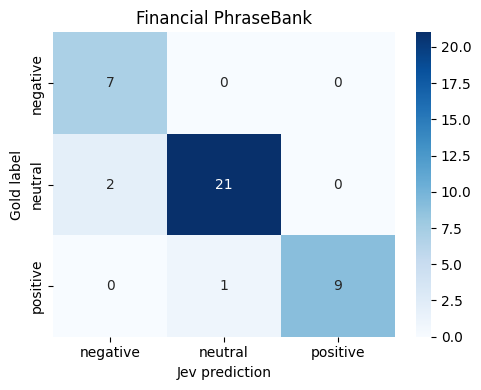

Twitter Financial News n= 40


,task,dataset,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,classification,Twitter Financial News,40,0.625,0.616931,0.629921,0.649038,0.758838


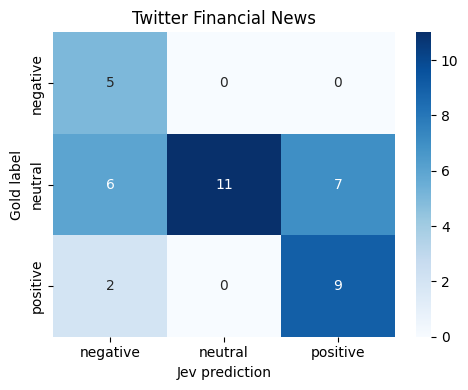

In [20]:
# Classification diagnostics
for name, result in classification_outputs.items():
    print(name, "n=", len(result))
    display(pd.DataFrame([benchmark_metrics[[m["dataset"] for m in benchmark_metrics].index(name)]]))
    cm = confusion_matrix(result.label, result.prediction, labels=LABELS)
    plt.figure(figsize=(5,4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel("Jev prediction"); plt.ylabel("Gold label"); plt.title(name); plt.tight_layout(); plt.show()


## 5. Sentiment regression (-1 to 1)

Use FiQA's provided test split when present. Jev returns the expected score for an ordered rubric. The 21 rubric levels span `-1.0 ... +1.0` in `0.1` increments; convert Jev's expected index `0 ... 20` linearly back to that range. Report MAE, RMSE, and R². If the dataset has no test split, use a reproducible held-out split.


In [21]:
fiqa = pd.read_csv(PATHS["fiqa"]).dropna(subset=["sentence", "sentiment_score"]).copy()
fiqa["sentiment_score"] = pd.to_numeric(fiqa.sentiment_score, errors="coerce")
fiqa = fiqa.dropna(subset=["sentiment_score"])
if "split" in fiqa and fiqa.split.astype(str).str.lower().eq("test").any():
    fiqa_test = fiqa[fiqa.split.astype(str).str.lower().eq("test")].copy()
else:
    _, fiqa_test = train_test_split(fiqa, test_size=.2, random_state=SEED)
fiqa_test = fiqa_test.reset_index(drop=True)
fiqa_test["_row_id"] = fiqa_test.index.astype(str)
fiqa_test["sentiment_score"] = fiqa_test.sentiment_score.clip(-1,1)
# Jev score rubrics support 2–10 ordered levels. Ten levels span FiQA's [-1, 1] range.
SCORE_VALUES = np.linspace(-1.0, 1.0, 10)
SCORE_CRITERIA = [
    f"Overall financial sentiment score {value:+.3f} on the -1 (very negative) to +1 (very positive) scale."
    for value in SCORE_VALUES
]

def regression_questions(_row):
    return {"sentiment_score":{"type":"score", "instructions":"Rate the overall sentiment expressed toward the named financial target. Use negative values for bearish/negative, zero for neutral or mixed, and positive values for bullish/positive. Focus on the target if provided.", "criteria":SCORE_CRITERIA}}

regression_pred = run_cached("sentiment_regression_fiqa", fiqa_test,
    regression_questions,
    lambda r: {"text":str(r.sentence), "target":str(r.get("target", "")), "aspects":str(r.get("aspects", ""))},
    REGRESSION_LIMIT)
regression_results = fiqa_test.merge(regression_pred, on="_row_id", how="inner")
def score_to_value(response):
    answer = get_answer(response, "sentiment_score")
    try: return float(np.clip(float(answer["score"]), 0, 9) * (2.0 / 9.0) - 1.0)
    except (KeyError, TypeError, ValueError): return np.nan
regression_results["prediction"] = regression_results.response.map(score_to_value)
regression_results = regression_results.dropna(subset=["prediction"])
y_true, y_pred = regression_results.sentiment_score, regression_results.prediction
regression_metrics = {"task":"regression", "dataset":"FiQA", "n":len(regression_results),
    "mae":mean_absolute_error(y_true,y_pred), "rmse":mean_squared_error(y_true,y_pred)**.5,
    "r2":r2_score(y_true,y_pred) if len(regression_results)>1 else np.nan}
display(pd.DataFrame([regression_metrics]))


sentiment_regression_fiqa: 60 selected, 0 cached, 60 API calls remain


sentiment_regression_fiqa:   0%|          | 0/60 [00:00<?, ?it/s]

,task,dataset,n,mae,rmse,r2
0,regression,FiQA,60,0.224383,0.263401,0.485431


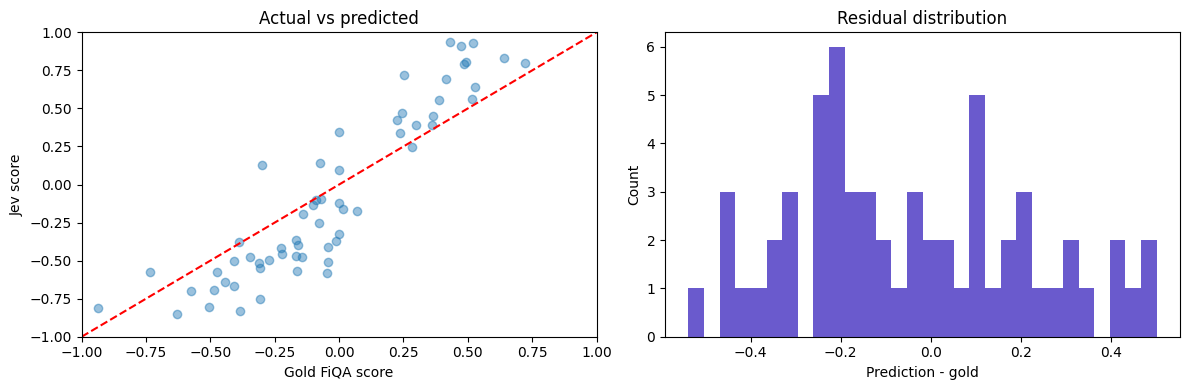

In [22]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(regression_results.sentiment_score, regression_results.prediction, alpha=.45)
axes[0].plot([-1,1],[-1,1],"r--"); axes[0].set(xlabel="Gold FiQA score", ylabel="Jev score", title="Actual vs predicted", xlim=(-1,1), ylim=(-1,1))
residual = regression_results.prediction - regression_results.sentiment_score
axes[1].hist(residual, bins=30, color="slateblue"); axes[1].set(xlabel="Prediction - gold", ylabel="Count", title="Residual distribution")
plt.tight_layout(); plt.show()


## 6. Multi-label ticker prediction

The large ticker-linking CSV is read with only the necessary columns. We build a time-based 70/15/15 split, grouping identical normalized article text together and deduplicating URLs to reduce leakage. This task makes **one Jev API request per article**, with one `noul` yes/no probability question for each ticker in that request. The validation sample chooses one global threshold for F1; the test sample is evaluated only after threshold selection. This is a costly task: reduce the limits while testing, then set them to `None` for the full validation/test splits.


In [15]:
ticker = pd.read_csv(PATHS["ticker"], usecols=["text","title","date_publish","url","mentioned_companies"], low_memory=False)
ticker = ticker.dropna(subset=["mentioned_companies"])
ticker["text"] = ticker.text.fillna("").astype(str)
ticker["title"] = ticker.title.fillna("").astype(str)
ticker["url"] = ticker.url.fillna("").astype(str)
ticker["_text_norm"] = ticker.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
ticker = ticker[ticker._text_norm.ne("")]
if ticker.url.ne("").any(): ticker = ticker.drop_duplicates(subset=["url"], keep="first")
ticker = ticker.drop_duplicates(subset=["_text_norm"], keep="first").reset_index(drop=True)
ticker["_date"] = pd.to_datetime(ticker.date_publish, errors="coerce", utc=True)
ticker = ticker.sort_values("_date", na_position="first").reset_index(drop=True)

def parse_labels(value):
    try: vals = json.loads(value) if isinstance(value,str) else value
    except Exception:
        try: vals = ast.literal_eval(value)
        except Exception: vals = []
    if not isinstance(vals, (list,tuple,set)): vals = [vals] if vals else []
    return sorted({str(v).strip().upper().replace("$", "") for v in vals if str(v).strip()})

ticker["gold_tickers"] = ticker.mentioned_companies.map(parse_labels)
ticker["_row_id"] = ticker.index.astype(str)
ticker["_split"] = "train"
n = len(ticker); test_start = int(n*.85); val_start = int(n*.70)
ticker.loc[val_start:test_start-1, "_split"] = "validation"
ticker.loc[test_start:, "_split"] = "test"
valid_mask = ticker.gold_tickers.map(lambda xs: any(x in TICKERS for x in xs))
ticker = ticker[valid_mask].reset_index(drop=True)
val_ticker = ticker[ticker._split.eq("validation")].copy()
test_ticker = ticker[ticker._split.eq("test")].copy()
print(f"Rows with at least one benchmark ticker: {len(ticker):,}; val={len(val_ticker):,}; test={len(test_ticker):,}")
print("Ticker label cardinality (first 12):")
display(ticker.gold_tickers.map(lambda xs: len(set(xs)&set(TICKERS))).describe())

def ticker_questions(_row):
    questions = {}
    for symbol in TICKERS:
        company = TICKER_ENTITY_NAMES.get(symbol, symbol)
        questions[symbol] = {"type":"noul", "instructions":f"Does this article refer to {company} ({symbol}) as a relevant company or security? Answer yes only when the article is about or explicitly discusses this company, not just an incidental unrelated mention.", "criteria":{"true":f"The article is about or explicitly discusses {company} ({symbol}).", "false":f"The article is not about or does not explicitly discuss {company} ({symbol})."}}
    return questions

def ticker_state(row):
    text = row.title + "\n\n" + row.text
    return {"article": text[:12000]}

val_pred = run_cached("ticker_validation", val_ticker, ticker_questions, ticker_state, TICKER_VALIDATION_LIMIT)
test_pred = run_cached("ticker_test", test_ticker, ticker_questions, ticker_state, TICKER_TEST_LIMIT)


Rows with at least one benchmark ticker: 59,684; val=8,909; test=8,908
Ticker label cardinality (first 12):


count    59684.000000
mean         1.375377
std          0.785746
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         11.000000
Name: gold_tickers, dtype: float64

ticker_validation: 30 selected, 30 cached, 0 API calls remain


ticker_validation:   0%|          | 0/30 [00:00<?, ?it/s]

ticker_test: 50 selected, 50 cached, 0 API calls remain


ticker_test:   0%|          | 0/50 [00:00<?, ?it/s]

In [16]:
def ticker_probability_frame(frame, pred):
    joined = frame.merge(pred, on="_row_id", how="inner")
    rows=[]
    for _, row in joined.iterrows():
        answers = row.response.get("answers", {})
        probs = {s: float(answers.get(s,{}).get("noul",0.0)) for s in TICKERS}
        rows.append({"_row_id":row._row_id, "gold_tickers":row.gold_tickers, **probs})
    return pd.DataFrame(rows)

val_probs = ticker_probability_frame(val_ticker, val_pred)
test_probs = ticker_probability_frame(test_ticker, test_pred)

def multilabel_arrays(frame, threshold):
    y = np.array([[int(symbol in set(labels)&set(TICKERS)) for symbol in TICKERS] for labels in frame.gold_tickers], dtype=int)
    p = frame[TICKERS].to_numpy(dtype=float) >= threshold
    return y,p

threshold_rows=[]
for threshold in np.arange(.05,.951,.025):
    vy,vp = multilabel_arrays(val_probs, threshold)
    threshold_rows.append((threshold, f1_score(vy,vp,average="macro",zero_division=0)))
if len(val_probs):
    best_threshold, val_macro_f1 = max(threshold_rows, key=lambda x:x[1])
else:
    best_threshold, val_macro_f1 = .5, np.nan
print("Validation-selected global threshold:", round(float(best_threshold),3), "macro F1:", val_macro_f1)

ty,tp = multilabel_arrays(test_probs, best_threshold)
test_metrics = {"task":"ticker multilabel", "dataset":"Financial News Ticker Linking", "n":len(test_probs),
    "threshold":float(best_threshold), "micro_precision":precision_score(ty,tp,average="micro",zero_division=0),
    "micro_recall":recall_score(ty,tp,average="micro",zero_division=0), "micro_f1":f1_score(ty,tp,average="micro",zero_division=0),
    "macro_precision":precision_score(ty,tp,average="macro",zero_division=0), "macro_recall":recall_score(ty,tp,average="macro",zero_division=0),
    "macro_f1":f1_score(ty,tp,average="macro",zero_division=0), "exact_match":float(np.mean(np.all(ty==tp,axis=1))),
    "hamming_loss":hamming_loss(ty,tp)}
# AP is undefined for labels with no positives in this test sample.
# Exclude those columns so sklearn does not warn "No positive class found in y_true".
test_scores = test_probs[TICKERS].to_numpy(dtype=float)
ap_label_mask = ty.sum(axis=0) > 0
test_metrics["macro_ap_label_count"] = int(ap_label_mask.sum())
if ap_label_mask.any():
    test_metrics["macro_average_precision"] = average_precision_score(
        ty[:, ap_label_mask], test_scores[:, ap_label_mask], average="macro")
else:
    test_metrics["macro_average_precision"] = np.nan
display(pd.DataFrame([test_metrics]))


Validation-selected global threshold: 0.05 macro F1: 0.14929981123415018


,task,dataset,n,threshold,micro_precision,micro_recall,micro_f1,macro_precision,macro_recall,macro_f1,exact_match,hamming_loss,macro_ap_label_count,macro_average_precision
0,ticker multilabel,Financial News Ticker Linking,50,0.05,0.366197,0.8125,0.504854,0.218425,0.32551,0.248839,0.24,0.041633,20,0.686989


,ticker,precision,recall,f1,gold_support,predicted_support
15,XOM,1.000000,1.00,1.000000,1,1
35,DIS,1.000000,1.00,1.000000,2,2
44,GS,1.000000,1.00,1.000000,6,6
3,AMZN,0.833333,1.00,0.909091,5,6
2,GOOGL,0.833333,1.00,0.909091,5,6
4,NVDA,0.666667,1.00,0.800000,2,3
20,BAC,0.666667,1.00,0.800000,2,3
9,V,0.600000,1.00,0.750000,6,10
0,AAPL,0.600000,1.00,0.750000,3,5
5,META,1.000000,0.60,0.750000,5,3


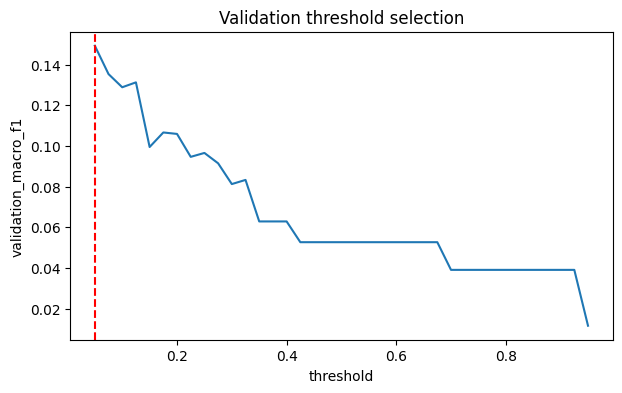

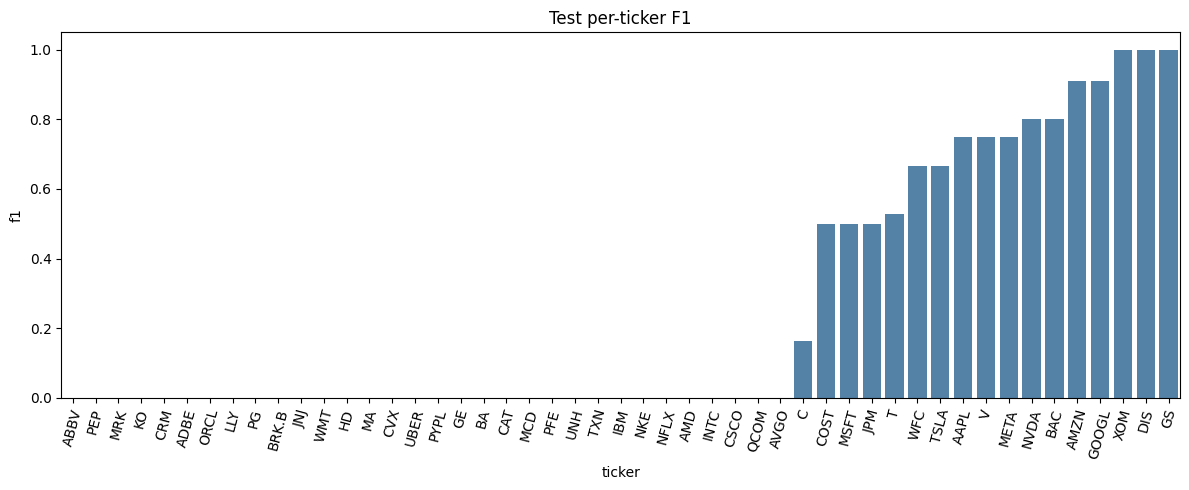

In [17]:
# Per-ticker performance, threshold sweep, and score distributions
per_ticker = pd.DataFrame({
    "ticker":TICKERS,
    "precision":precision_score(ty,tp,average=None,zero_division=0),
    "recall":recall_score(ty,tp,average=None,zero_division=0),
    "f1":f1_score(ty,tp,average=None,zero_division=0),
    "gold_support":ty.sum(axis=0),
    "predicted_support":tp.sum(axis=0),
}).sort_values("f1",ascending=False)
display(per_ticker)
if len(val_probs):
    sweep = pd.DataFrame(threshold_rows,columns=["threshold","validation_macro_f1"])
    plt.figure(figsize=(7,4)); sns.lineplot(data=sweep,x="threshold",y="validation_macro_f1"); plt.axvline(best_threshold,color="red",linestyle="--"); plt.title("Validation threshold selection"); plt.show()
plt.figure(figsize=(12,5)); sns.barplot(data=per_ticker.sort_values("f1"),x="ticker",y="f1",color="steelblue"); plt.xticks(rotation=75); plt.title("Test per-ticker F1"); plt.tight_layout(); plt.show()


## 7. Save benchmark outputs

The output folder contains task metrics, row-level predictions, and per-ticker scores. Successful API responses remain cached so reruns can continue without repeating completed calls. Failed calls are logged in the cache and will be retried on a later run.


In [23]:
all_metrics = benchmark_metrics + [regression_metrics, test_metrics]
metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(OUTPUT_DIR / "benchmark_metrics.csv", index=False)
for name, frame in classification_outputs.items():
    fname = "classification_" + re.sub(r"\W+", "_", name.lower()) + "_predictions.csv"
    frame.drop(columns=["response"],errors="ignore").to_csv(OUTPUT_DIR/fname,index=False)
regression_results.drop(columns=["response"],errors="ignore").to_csv(OUTPUT_DIR/"fiqa_regression_predictions.csv",index=False)
test_probs.assign(predicted_tickers=["|".join(np.array(TICKERS)[row]) for row in tp]).to_csv(OUTPUT_DIR/"ticker_test_predictions.csv",index=False)
per_ticker.to_csv(OUTPUT_DIR/"ticker_performance.csv",index=False)
print("Saved outputs:", OUTPUT_DIR)
display(metrics_df)


Saved outputs: /kaggle/working/jev_financial_nlp


,task,dataset,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mae,rmse,r2,threshold,micro_precision,micro_recall,micro_f1,exact_match,hamming_loss,macro_ap_label_count,macro_average_precision
0,classification,Financial PhraseBank,40,0.925,0.918567,0.926634,0.910774,0.937681,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,classification,Twitter Financial News,40,0.625,0.616931,0.629921,0.649038,0.758838,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,regression,FiQA,60,NaN,NaN,NaN,NaN,NaN,0.224383,0.263401,0.485431,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ticker multilabel,Financial News Ticker Linking,50,NaN,0.248839,NaN,0.218425,0.325510,NaN,NaN,NaN,0.05,0.366197,0.8125,0.504854,0.24,0.041633,20.0,0.686989
